In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
import numpy as np
import GDLModules.util as util
import plotly.express as px
import torch.nn as nn
import torch
import GDLModules.A_CAE as A_CAE
import GDLModules.A_AE as A_AE
from datasets import load_dataset
import matplotlib.pyplot as plt
from sklearn.datasets import make_s_curve

import copy
import panel as pn

pn.extension("plotly", comms="ipywidgets")

In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

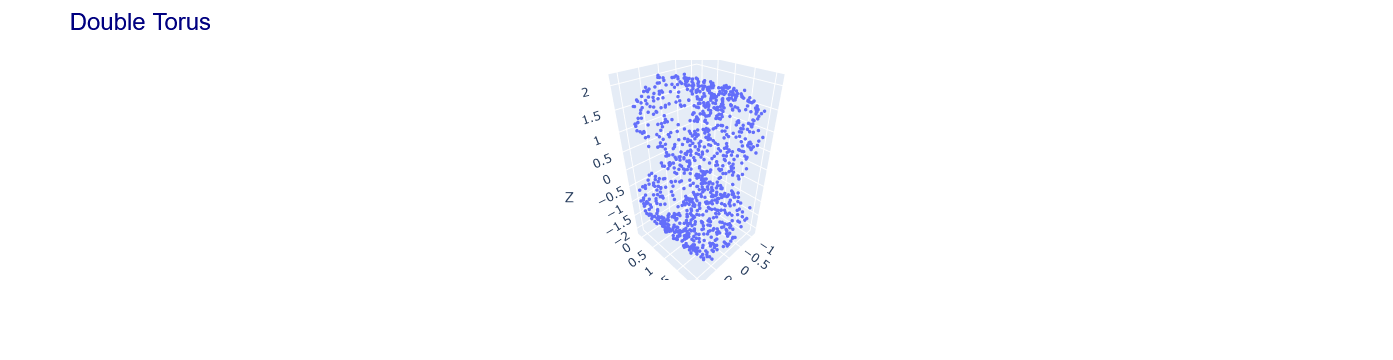

In [18]:
s_data, _ = make_s_curve(n_samples=1000, noise=0.05, random_state=0)
s_data_test, _ = make_s_curve(n_samples=1000, noise=0.05, random_state=1)
util.plot3d([(s_data, "S-Curve Dataset")], title="Double Torus") 

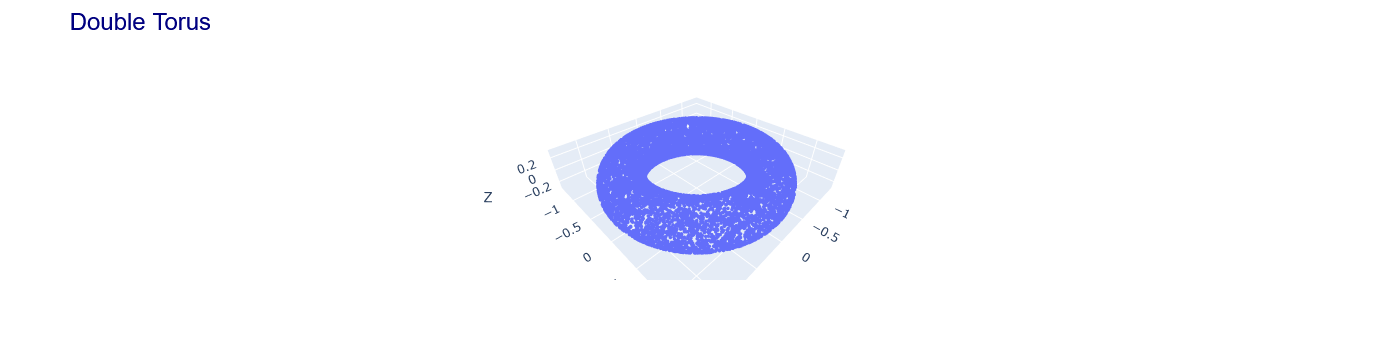

In [19]:
torus_data = util.generate_torus(10000)
torus_data_test = util.generate_torus(10000)
util.plot3d([(torus_data, "torus data")], title="Double Torus")

In [20]:
X_train = torch.tensor(torus_data, dtype=torch.float32).to(device)
X_test = torch.tensor(torus_data_test, dtype=torch.float32).to(device)
X_loader_train = torch.utils.data.DataLoader(X_train, batch_size=1024, shuffle=True)
X_loader_test = torch.utils.data.DataLoader(X_test, batch_size=1024, shuffle=True)

In [21]:

def reconstruct(model_name, data):
    if model_name == "ae":
        ae.to(device)
        reconstructed = ae.decode(ae.encode(data)).cpu().detach().numpy()
        reconstructed.shape
        return reconstructed
    if model_name == "cae":
        cae.to(device)
        probabilities = cae.true_predict(data)
        chart_indexes = torch.argmax(probabilities, dim=1).to(device)
        reconstructed = cae.decode(cae.encode(data, chart_indexes), chart_indexes).cpu().detach().numpy()

        return reconstructed, chart_indexes


In [15]:
ae = A_AE.AE(3,2,15)
A_AE.train_wae(num_epochs=5, x_train_loader=X_loader_train, network=ae, device=device, mmd_weight=1.0)

100%|██████████| 5/5 [00:01<00:00,  3.51it/s]


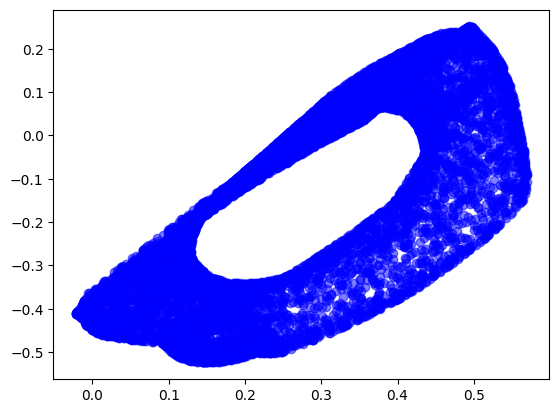

In [16]:
ae.to(device)
encoded = ae.encode(X_test).cpu().detach().numpy()
encoded.shape
plt.scatter(encoded[:, 0], encoded[:, 1], c='blue', alpha=0.5)

In [17]:
reconstructed = reconstruct("ae", X_train[0:10000])
util.plot3d([(reconstructed, "reconstructed")], title="Double Torus")

In [18]:
cae = A_CAE.CAE(x_dim=3, z_dim=2, hidden_structure=[15,15], chart_amount=10, activation=nn.Tanh()).to(device)

A_CAE.pre_train_cae(num_epochs=50, x_train=X_train, network=cae, device = device, lr=1e-2)
pretrained = copy.deepcopy(cae)


100%|██████████| 50/50 [00:01<00:00, 33.07it/s]


[autoreload of GDLModules.A_CAE failed: Traceback (most recent call last):
  File "d:\Miniconda3\envs\test\Lib\site-packages\IPython\extensions\autoreload.py", line 283, in check
    superreload(m, reload, self.old_objects)
  File "d:\Miniconda3\envs\test\Lib\site-packages\IPython\extensions\autoreload.py", line 483, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "d:\Miniconda3\envs\test\Lib\importlib\__init__.py", line 131, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 995, in exec_module
  File "<frozen importlib._bootstrap_external>", line 1133, in get_code
  File "<frozen importlib._bootstrap_external>", line 1063, in source_to_code
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "D:\Documents_D\Geometric-Deep-Learning\src\GDLModules\A_CAE.py", line 296
    def detect_problem_area()
                     

tensor(5.4629e-07)

In [21]:
cae = copy.deepcopy(pretrained)
diag = A_CAE.train_cae(num_epochs=1, x_train_loader=X_loader_train, network=cae, device=device, lr=1e-2, best_k=1, mmd_weight=0.0, lipschitz_weight=0.0)
posttrained = copy.deepcopy(cae)

100%|██████████| 1/1 [00:01<00:00,  1.37s/it, loss=-0.3691%, lr=0.010000, mmd_loss=52.9546%, rec_loss=-0.4472%]


In [ ]:
cae = posttrained
reconstructed, alpha = reconstruct("cae", X_train[0:10000])
util.plot3d([(reconstructed, "reconstructed")], title="Double Torus", color=[alpha.detach().numpy()])

D:\Documents_D\Geometric-Deep-Learning\src\GDLModules\A_CAE.py:73: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  chart_index = torch.tensor(chart_index, device=x.device)
<string>:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).


torch.Size([2])


AttributeError: 'numpy.ndarray' object has no attribute 'cpu'

In [22]:
cae = copy.deepcopy(posttrained)
diag = A_CAE.train_cae(num_epochs=1, x_train_loader=X_loader_train, network=cae, device=device, lr=1e-3, best_k=1, mmd_weight=0.0, lipschitz_weight=0.05)
lipschitz_trained = copy.deepcopy(cae)

100%|██████████| 1/1 [00:01<00:00,  1.47s/it, loss=11.4194%, lr=0.001000, mmd_loss=47.6794%, rec_loss=-0.5948%]


In [23]:


from GDLModules.viser_viz import open_split_view


sw = open_split_view(X_test, cae)
print("Press Enter to close the viewer...")
input()
sw.close()


╭──────────────── viser ────────────────╮
│             ╷                         │
│   HTTP      │ http://127.0.0.1:8080   │
│   Websocket │ ws://127.0.0.1:8080     │
│             ╵                         │
╰───────────────────────────────────────╯

╭──────────────── viser ────────────────╮
│             ╷                         │
│   HTTP      │ http://127.0.0.1:8081   │
│   Websocket │ ws://127.0.0.1:8081     │
│             ╵                         │
╰───────────────────────────────────────╯

Press Enter to close the viewer...


(viser) Connection opened (0, 1 total), 77 persistent messages

(viser) Connection opened (0, 1 total), 95 persistent messages

(viser) Connection closed (0, 0 total)

(viser) Connection closed (0, 0 total)

(viser) Server stopped

(viser) Server stopped

# Visual training


In [8]:
cae = A_CAE.CAE(x_dim=3, z_dim=2, hidden_structure=[15,15], chart_amount=10, activation=nn.Tanh()).to(device)

A_CAE.pre_train_cae(num_epochs=50, x_train=X_train, network=cae, device = device, lr=1e-2)
pretrained = copy.deepcopy(cae)


100%|██████████| 50/50 [00:02<00:00, 22.44it/s]


In [10]:

import copy
import threading
import time

import torch
import plotly.graph_objects as go
from IPython.display import display

# --------------------------------------------------
# Model and evaluation data
# --------------------------------------------------
restart_training = False

if(restart_training):
    cae = copy.deepcopy(pretrained)

plot_data = X_test[:10000].detach()
plot_data = plot_data.to(next(cae.parameters()).device)

stop_event = threading.Event()


threshold = 0.005

@torch.no_grad()
def plot_values():
    points = []
    colors = []

    for i in range(cae.chart_amount):
        reconstructed = cae.decode(cae.encode(plot_data, i), i)
        errors = ((reconstructed - plot_data) ** 2).sum(dim=1)
        accepted = errors < threshold

        selected = reconstructed[accepted]
        points.append(selected)
        colors.append(torch.full(
            (len(selected),),
            i,
            device=plot_data.device,
            dtype=torch.long,
        ))

    return (
        torch.cat(points, dim=0).cpu().numpy(),
        torch.cat(colors, dim=0).cpu().numpy(),
    )

# --------------------------------------------------
# Record history
# --------------------------------------------------

history = []
start_time = time.monotonic()


def update():
    points, colors = plot_values()
    elapsed = time.monotonic() - start_time

    history.append((
        elapsed,
        points.copy(),
        colors.copy(),
    ))


# --------------------------------------------------
# Start training
# --------------------------------------------------

thread = threading.Thread(
    target=A_CAE.train_cae,
    args=(200, X_loader_train, cae, device),
    kwargs={
        "lr": 1e-3,
        "best_k": 1,
        "mmd_weight": 0.0,
        "lipschitz_weight": 0.0,
        "stop_event": stop_event,
        "threshold": threshold,
    },
)

thread.start()


# --------------------------------------------------
# Original loop
# --------------------------------------------------

try:
    while True:
        update()
        time.sleep(1)

except KeyboardInterrupt:
    print("Stopped")
    stop_event.set()


# --------------------------------------------------
# Construct interactive history
# --------------------------------------------------

def make_history_plot(history):
    if not history:
        raise ValueError("No snapshots were recorded.")

    t0, points, colors = history[0]

    fig = util.plot3d(
        [(points, "reconstructed")],
        title="Training reconstruction",
        color=[colors],
    )

    fig.update_layout(
        uirevision="keep-camera",
        showlegend=False,
    )

    fig.update_scenes(
        uirevision="keep-camera",
        aspectmode="cube",
        xaxis_range=[-1.5, 1.5],
        yaxis_range=[-1.5, 1.5],
        zaxis_range=[-1.5, 1.5],
    )

    # Each frame contains a complete saved reconstruction
    frames = []

    for i, (elapsed, points, colors) in enumerate(history):
        frames.append(
            go.Frame(
                name=str(i),
                data=[
                    go.Scatter3d(
                        x=points[:, 0],
                        y=points[:, 1],
                        z=points[:, 2],
                        marker=dict(color=colors),
                    )
                ],
                traces=[0],
            )
        )

    fig.frames = frames

    # Plotly-native slider
    steps = []

    for i, (elapsed, _, _) in enumerate(history):
        steps.append(
            dict(
                method="animate",
                label=f"{elapsed:.1f}",
                args=[
                    [str(i)],
                    dict(
                        mode="immediate",
                        frame=dict(
                            duration=0,
                            redraw=True,
                        ),
                        transition=dict(duration=0),
                    ),
                ],
            )
        )

    fig.update_layout(
        sliders=[
            dict(
                active=0,
                currentvalue=dict(
                    prefix="Training time: ",
                    suffix=" s",
                ),
                pad=dict(t=40),
                steps=steps,
            )
        ],
        margin=dict(b=100),
    )

    return fig

import plotly.io as pio

pio.renderers.default = "browser"
# Show the saved history after stopping
fig = make_history_plot(history)
fig.show()


100%|██████████| 200/200 [07:04<00:00,  2.12s/it, loss=-0.5719%, lr=0.001000, mmd_loss=12.2356%, rec_loss=-0.5631%]


Stopped


In [16]:
stop_event.set()
server.stop()

 33%|███▎      | 66/200 [01:03<01:50,  1.22it/s, loss=0.2673%, lr=0.001000, rec_loss=0.2718%]

 34%|███▎      | 67/200 [01:03<02:06,  1.05it/s, loss=0.2658%, lr=0.001000, rec_loss=0.2551%]


Training stopped.


# Graph experiments


In [7]:
if "graph_server" in globals():
    graph_server.stop()

import importlib
import GDLModules.graph_viz as graph_viz

importlib.reload(graph_viz)

graph_server = graph_viz.open_graph_view(
    X_train, radius=0.05, k=10, port=5006
)

Launching server at http://127.0.0.1:5006
